<a href="https://colab.research.google.com/github/Koroush-Mashayekh/diabetes-risk-prediction/blob/main/notebooks/03_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Diabetes Risk Prediction: Final Evaluation

The model selected in [`02_modeling.ipynb`](02_modeling.ipynb), **Logistic Regression (balanced)**,
is trained on the full training set and evaluated **once** on the held-out test set.

## 0. Data and final model
The same stratified split as in `02_modeling.ipynb` (`random_state=42`) is recreated, and the selected pipeline is trained on the full training set.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

URL = "https://raw.githubusercontent.com/Koroush-Mashayekh/diabetes-risk-prediction/main/data/diabetes.csv"
df = pd.read_csv(URL)

X = df.drop(columns="Outcome")
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

cols_with_hidden_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
X_train = X_train.copy()
X_test = X_test.copy()
X_train[cols_with_hidden_missing] = X_train[cols_with_hidden_missing].replace(0, np.nan)
X_test[cols_with_hidden_missing] = X_test[cols_with_hidden_missing].replace(0, np.nan)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (614, 8)  Test: (154, 8)


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

final_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced")),
])

final_model.fit(X_train, y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

## 1. Test set performance

In [3]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, roc_auc_score

y_pred = final_model.predict(X_test)
y_proba = final_model.predict_proba(X_test)[:, 1]

print("ROC-AUC:  ", round(roc_auc_score(y_test, y_proba), 3))
print("Recall:   ", round(recall_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Accuracy: ", round(accuracy_score(y_test, y_pred), 3))

ROC-AUC:   0.813
Recall:    0.704
Precision: 0.603
Accuracy:  0.734


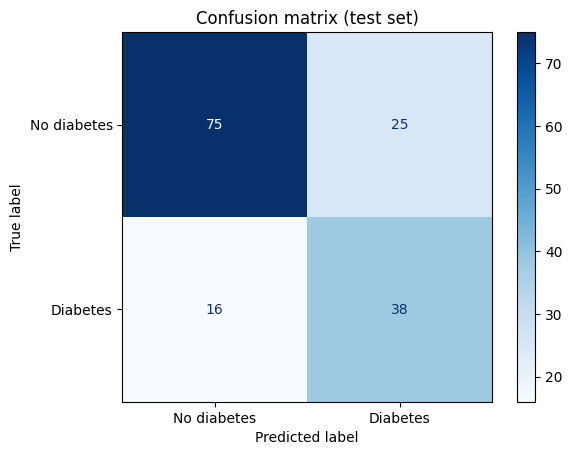

In [4]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["No diabetes", "Diabetes"],
    cmap="Blues"
)
plt.title("Confusion matrix (test set)")
plt.show()

**Result (test set, n = 154):**

| Metric    | CV (train)    | Test  |
|-----------|---------------|-------|
| ROC-AUC   | 0.844 ± 0.016 | 0.813 |
| Recall    | 0.701         | 0.704 |
| Precision | –             | 0.603 |
| Accuracy  | 0.762         | 0.734 |

- The model detects **38 of 54** diabetic patients (recall 0.70) and misses **16**.
- **25 of 100** non-diabetic patients receive a false alarm (precision 0.60).
- Test performance is consistent with cross-validation. The slightly lower ROC-AUC is expected
  given the small test set, where a few samples can shift the score noticeably.
- In a screening context, false alarms (leading to a follow-up test) are generally less costly
  than missed patients, which motivated the use of `class_weight="balanced"`.

## 2. ROC curve

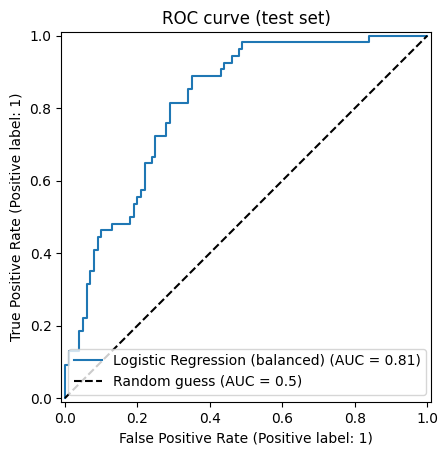

In [5]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_test, y_proba, name="Logistic Regression (balanced)")
plt.plot([0, 1], [0, 1], "k--", label="Random guess (AUC = 0.5)")
plt.title("ROC curve (test set)")
plt.legend()
plt.show()

The ROC curve lies well above the random-guess diagonal (AUC = 0.813). Moving along the curve corresponds
to changing the decision threshold: a lower threshold detects more diabetic patients at the cost of more false alarms.

## 3. Model interpretation
Logistic regression coefficients show how each feature influences the predicted risk.
Since features are standardized, coefficients are directly comparable: they show the effect of a
**one standard deviation increase** in each feature.

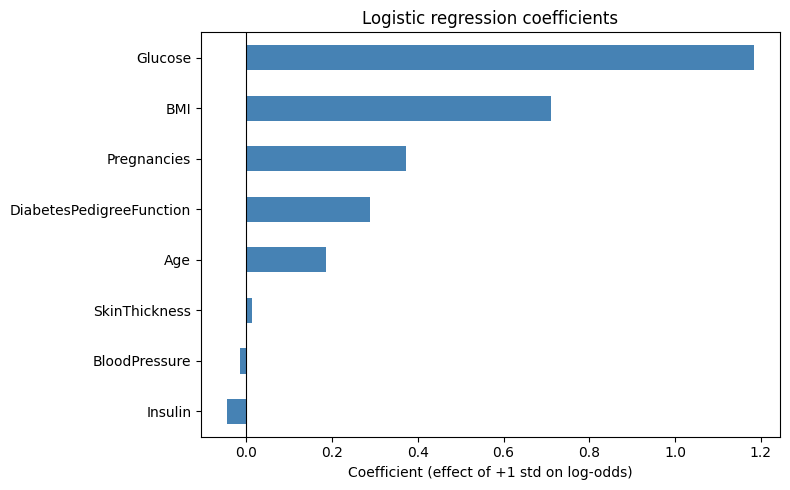

,coefficient,odds_ratio
Glucose,1.183,3.27
BMI,0.710,2.03
Pregnancies,0.373,1.45
DiabetesPedigreeFunction,0.288,1.33
Age,0.186,1.20
SkinThickness,0.014,1.01
BloodPressure,-0.015,0.99
Insulin,-0.045,0.96


In [6]:
coefs = pd.Series(
    final_model.named_steps["model"].coef_[0],
    index=X.columns
).sort_values()

coefs.plot(kind="barh", figsize=(8, 5), color="steelblue")
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Logistic regression coefficients")
plt.xlabel("Coefficient (effect of +1 std on log-odds)")
plt.tight_layout()
plt.show()

pd.DataFrame({
    "coefficient": coefs.round(3),
    "odds_ratio": np.exp(coefs).round(2)
}).sort_values("coefficient", ascending=False)

**Interpretation:**
- **Glucose** is by far the strongest predictor (odds ratio ≈ 3.3 per standard deviation),
  followed by **BMI** (≈ 2.0). This is consistent with the EDA and with clinical knowledge.
- **Insulin** has a near-zero coefficient despite its correlation with the outcome (0.30).
  It is correlated with Glucose (0.58), so it adds little unique information, and ~47% of its values were imputed.
  Univariate correlation is not the same as importance in a multivariable model.

## 4. Conclusion
A simple, interpretable pipeline (median imputation → standardization → balanced logistic regression)
reaches **ROC-AUC 0.81** and **recall 0.70** on unseen test data, clearly outperforming the naive baseline.
More complex models did not improve performance on this small dataset.

**Limitations:**
- Small dataset (768 patients), so test metrics have high variance.
- Population is limited to Pima Indian women aged 21+; results may not generalize to other populations.
- Insulin and SkinThickness have many missing values; median imputation is a simplification.